In [2]:
import pandas as pd

df = pd.read_csv("insurance.csv")

df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [9]:
df.duplicated().sum()

np.int64(1)

In [11]:
df[df.duplicated(keep=False)]

,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


In [10]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


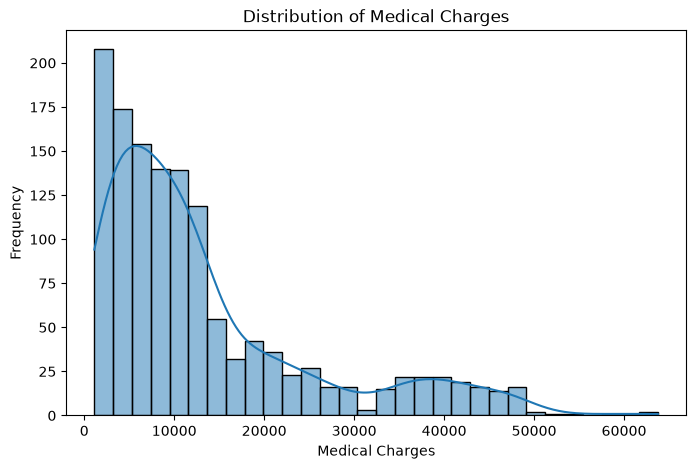

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="charges",
    bins=30,
    kde=True
)

plt.title("Distribution of Medical Charges")
plt.xlabel("Medical Charges")
plt.ylabel("Frequency")

plt.show()

In [13]:
df.groupby("smoker")["charges"].agg(
    ["count", "mean", "median"]
).round(2)

,count,mean,median
smoker,,,
no,1064,8434.27,7345.41
yes,274,32050.23,34456.35


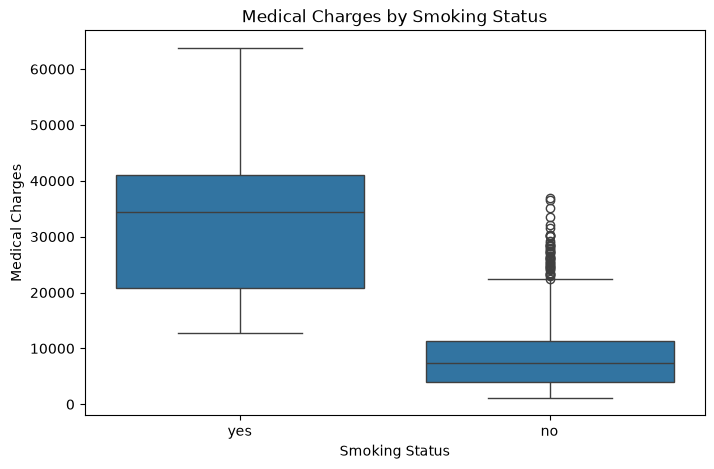

In [14]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="smoker",
    y="charges"
)

plt.title("Medical Charges by Smoking Status")
plt.xlabel("Smoking Status")
plt.ylabel("Medical Charges")

plt.show()

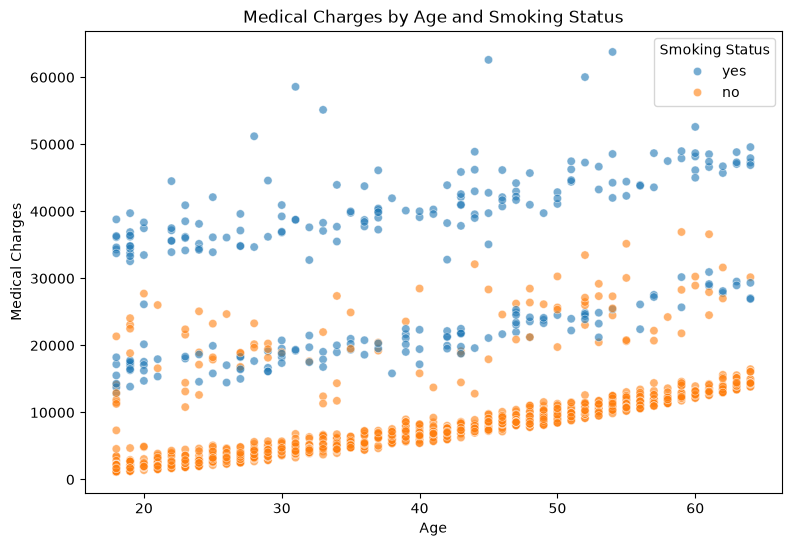

In [15]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="age",
    y="charges",
    hue="smoker",
    alpha=0.6
)

plt.title("Medical Charges by Age and Smoking Status")
plt.xlabel("Age")
plt.ylabel("Medical Charges")

plt.legend(title="Smoking Status")

plt.show()

In [16]:
df_corr = df.copy()

df_corr["smoker_binary"] = (
    df_corr["smoker"] == "yes"
).astype(int)

features = [
    "age",
    "bmi",
    "children",
    "smoker_binary",
    "charges"
]

corr = df_corr[features].corr()

corr.round(2)

,age,bmi,children,smoker_binary,charges
age,1.00,0.11,0.04,-0.03,0.30
bmi,0.11,1.00,0.01,0.00,0.20
children,0.04,0.01,1.00,0.01,0.07
smoker_binary,-0.03,0.00,0.01,1.00,0.79
charges,0.30,0.20,0.07,0.79,1.00


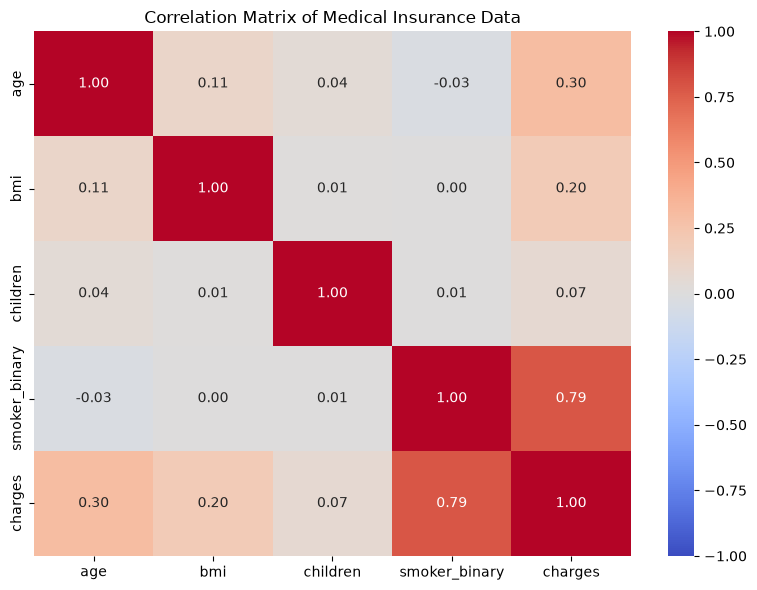

In [18]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of Medical Insurance Data")

plt.tight_layout()
plt.show()

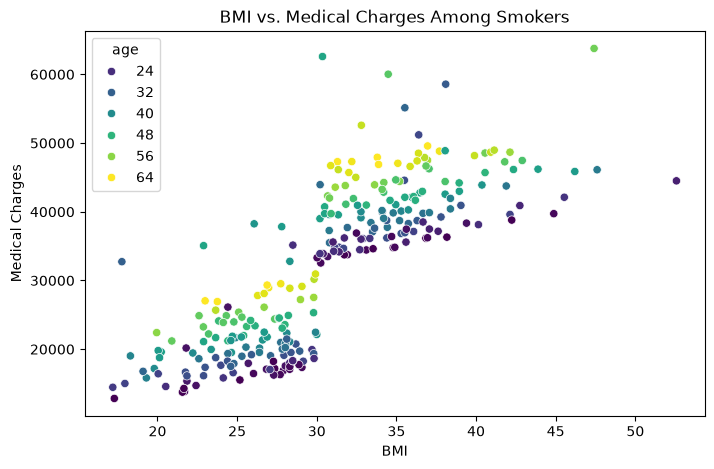

In [19]:
smokers = df[df["smoker"] == "yes"]

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=smokers,
    x="bmi",
    y="charges",
    hue="age",
    palette="viridis"
)

plt.title("BMI vs. Medical Charges Among Smokers")
plt.xlabel("BMI")
plt.ylabel("Medical Charges")

plt.show()

In [20]:
smokers = df[df["smoker"] == "yes"].copy()

smokers["bmi_group"] = smokers["bmi"].ge(30).map({
    False: "BMI < 30",
    True: "BMI >= 30"
})

smokers.groupby("bmi_group")["charges"].agg(
    ["count", "mean", "median"]
).round(2)

,count,mean,median
bmi_group,,,
BMI < 30,129,21363.22,20167.34
BMI >= 30,145,41557.99,40904.20
